# Preprocess holograms and painted support

Set `SATURATED_SCAN`, `LOOP_SCAN`, and `DARK_SCAN` in the first cell. Run the FTH preview cell to save `supportmask_<SATURATED_SCAN>_pre.png`. Paint the support pure red in Paint, save as `supportmask_<SATURATED_SCAN>.png` without resizing, then load and check it in notebook 01. Detector-mask loading and preprocessing settings remain below. No profile files are read.

Detector masks use the scan-pair painted PNG on the centered detector grid. No JSON polygon coordinates are loaded. Automatic detector exclusions are saved separately so later PNG edits can replace earlier painted masks.


In [1]:
from pathlib import Path
import os, sys, json
import h5py
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "reconstruction_inputs.py").is_file():
    HERE = HERE / "aperiodic_ajajas"
if not (HERE / "reconstruction_inputs.py").is_file():
    raise FileNotFoundError("Run from the repository root or aperiodic_ajajas")
REPO = HERE.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(HERE))
from library.phase_retrieval_geometry import recenter_source_support, recenter_modal_supports, _resample_spatial
from reconstruction_inputs import (
    DETECTOR_DATASET, scan_files, scan_metadata, detector_file_point_indices, currents_for_detector_files, point_mean,
    centered, support_field_coverage, prepare_point,
)

from aperiodic_ajajas.result_io import prepare_painted_detector_mask, save_detector_mask_template

RAW_ROOT = Path("/media/riccardo/EXT_16TB1/DATA/P04/11022228/raw")
PREFIX = "2602_orbitronics"


SATURATED_SCAN = 2923
LOOP_SCAN = 2924
LOOP_SCAN = 2925
DARK_SCAN = 2926

SATURATED_SCAN = 2871
LOOP_SCAN = 2872
LOOP_SCAN = 2873
DARK_SCAN = 2870

SATURATED_SCAN = 2919
LOOP_SCAN = 2920
#LOOP_SCAN = 2922
DARK_SCAN = 2921


#SATURATED_SCAN = 2930
#LOOP_SCAN = 2931
#DARK_SCAN = 2929

SATURATED_SCAN = 2923
LOOP_SCAN = 2924
LOOP_SCAN = 2925
DARK_SCAN = 2926


LOOP_POINT_STEP = 1  # Process point numbers 0, 5, ..., 100; set 1 for all points.

# Optional selections: None uses all points/frames.
LOOP_POINT_NUMBERS = None
SATURATED_POINT_NUMBERS = None
DARK_POINT_NUMBERS = None
LOOP_FRAME_INDICES = None
SATURATED_FRAME_INDICES = None
DARK_FRAME_INDICES = None
DETECTOR_CENTER = (1021, 891)  # Row, column; verify on scans 2923/2924.
SUPPORT_PNG = HERE / f"supportmask_{SATURATED_SCAN}.png"
SUPPORT_PRE_PNG = HERE / f"supportmask_{SATURATED_SCAN}_pre.png"
DETECTOR_MASK_PRE_PNG = HERE / f"mask_pixel_{SATURATED_SCAN}_pre.png"
DETECTOR_MASK_PNG = HERE / f"mask_pixel_{SATURATED_SCAN}.png"
DETECTOR_MASK_FLATTEN_SIGMA = 30.0  # Gaussian width in detector pixels; 0 gives plain log scale.
DETECTOR_MASK_FLATTEN_STRENGTH = 0.75  # 0=log only; 1=full smooth-background subtraction.
DETECTOR_MASK_DISPLAY_PERCENTILES = (0.5, 99.5)
CROP = 0  # Keep the full 2048-pixel detector image after centering.
BINNING = 1  # Copy2 working CDI loop uses no binning.
RETRIEVAL_CROP = 400  # Anticipated phase-retrieval detector crop.
RETRIEVAL_BINNING = 2  # Both 01 and 02 retrieve on the bin-2 grid.
RETRIEVAL_MODES = [1, 2]  # Check the enlarged support too.
BEAMSTOP_RADIUS = 0  # Paint beamstop exclusions in the detector PNG.
SATURATION = 2**16  # Copy2 oversaturation threshold.
PHOTON_LEVEL = 6.0  # Keep corrected signal > 6; None disables thresholding.
if PHOTON_LEVEL is not None and not np.isfinite(PHOTON_LEVEL):
    raise ValueError("PHOTON_LEVEL must be finite or None")
# Optional one-frame photon diagnostic, run before any full scan is averaged.
RUN_PHOTON_DIAGNOSTIC = True
PHOTON_DIAGNOSTIC_SCAN = LOOP_SCAN
PHOTON_DIAGNOSTIC_POINT = (LOOP_POINT_NUMBERS[0] if LOOP_POINT_NUMBERS else 0)
PHOTON_DIAGNOSTIC_FRAME = (LOOP_FRAME_INDICES[0] if LOOP_FRAME_INDICES else 0)
PHOTON_DIAGNOSTIC_CORNER = (slice(-100, None), slice(0, 100))
PHOTON_DIAGNOSTIC_HIST_BINS = 400
PHOTON_DIAGNOSTIC_HIST_RANGE = None  # None uses robust data percentiles.
DARK_CORNER_ROI = (slice(190, 400), slice(190, 400))  # Prepared detector grid; exclude mask_pixel.
DARK_CORRECTION_MODE = "measured"  # "measured", "corner_fit", or "manual".
DARK_MANUAL_SCALE = 1.0  # Used only with DARK_CORRECTION_MODE="manual".
DARK_MANUAL_OFFSET = 0.0  # Detector counts per frame, used only in manual mode.
if PHOTON_LEVEL is not None and not np.isfinite(PHOTON_LEVEL):
    raise ValueError("PHOTON_LEVEL must be finite or None")
CACHE = HERE / "processed" / f"preprocessed_{LOOP_SCAN}_{SATURATED_SCAN}.h5"
SUPPORT_QA = HERE / "processed" / f"support_overlay_{SATURATED_SCAN}.png"
if not CACHE.resolve().is_relative_to(REPO.resolve()):
    raise ValueError("CACHE must be inside this repository")
CACHE.parent.mkdir(parents=True, exist_ok=True)

def select_numbers(available, requested=None):
    available = [int(value) for value in available]
    if requested is None:
        return list(range(len(available)))
    if not requested or len(set(requested)) != len(requested):
        raise ValueError("Choose a nonempty list of distinct point numbers")
    missing = set(requested) - set(available)
    if missing:
        raise ValueError(f"Unavailable point numbers: {sorted(missing)}")
    return [available.index(value) for value in requested]


## Inspect scan files and point metadata

In [2]:
if type(LOOP_POINT_STEP) is not int or LOOP_POINT_STEP < 1:
    raise ValueError("LOOP_POINT_STEP must be a positive integer")
sat_master, sat_files = scan_files(RAW_ROOT, PREFIX, SATURATED_SCAN)
sat_files = [sat_files[i] for i in select_numbers(
    detector_file_point_indices(sat_files), SATURATED_POINT_NUMBERS)]
loop_master, all_loop_files = scan_files(RAW_ROOT, PREFIX, LOOP_SCAN)
all_loop_indices = detector_file_point_indices(all_loop_files)
# Explicit point numbers are exact; otherwise preserve acquisition-number stride.
requested_loop_points = (LOOP_POINT_NUMBERS if LOOP_POINT_NUMBERS is not None else
                         [int(v) for v in all_loop_indices if v % LOOP_POINT_STEP == 0])
loop_files = [all_loop_files[i] for i in select_numbers(all_loop_indices, requested_loop_points)]
sat_energy, sat_current_full = scan_metadata(sat_master)
sat_point_indices, sat_current = currents_for_detector_files(sat_current_full, sat_files)
loop_energy, loop_current_full = scan_metadata(loop_master)
loop_point_indices, loop_current = currents_for_detector_files(loop_current_full, loop_files)


## Create the image to paint
Run the next cell, paint the exported PNG red, and save it under the printed support filename. Notebook 01 loads and checks that file.


In [3]:
# Average the saturated-reference files. Keep frame reading in point_mean so
# one 100-frame stack does not have to remain in memory.
reference_sum = None
for index, path in enumerate(sat_files):
    point = point_mean(path, frame_indices=SATURATED_FRAME_INDICES)
    if reference_sum is None:
        reference_sum = np.zeros_like(point, dtype=np.float64)
    reference_sum += point
    print(f"Averaged {index + 1}/{len(sat_files)} saturated files", end="\r")
print()
reference_raw = (reference_sum / len(sat_files)).astype(np.float32)

if DARK_SCAN is None:
    dark = np.zeros_like(reference_raw)
else:
    _, dark_files = scan_files(RAW_ROOT, PREFIX, DARK_SCAN)
    dark_files = [dark_files[i] for i in select_numbers(
        detector_file_point_indices(dark_files), DARK_POINT_NUMBERS)]
    dark_sum = np.zeros_like(reference_sum)
    for index, path in enumerate(dark_files):
        dark_sum += point_mean(path, frame_indices=DARK_FRAME_INDICES)
        print(f"Averaged {index + 1}/{len(dark_files)} dark files", end="\r")
    print()
    dark = (dark_sum / len(dark_files)).astype(np.float32)

# Export an FTH painting template before loading any support mask.
# Open this PNG in Paint, mark the support with pure red (255, 0, 0),
# and Save As a separate PNG without resizing it.
from library import fthcore as fth
FTH_PAINT_TEMPLATE = SUPPORT_PRE_PNG
fth_paint_object = fth.reconstruct(reference_raw - dark)
fth_paint_view = np.log1p(np.abs(fth_paint_object))
fth_paint_low, fth_paint_high = np.percentile(fth_paint_view, [1, 99.8])
fth_paint_gray = np.clip(
    (fth_paint_view - fth_paint_low) / max(float(fth_paint_high - fth_paint_low), 1e-12),
    0, 1,
)
# Reserve red-channel value 255 for support pixels, including at bright highlights.
fth_paint_rgb = np.repeat((254 * fth_paint_gray).astype(np.uint8)[..., None], 3, axis=-1)
FTH_PAINT_TEMPLATE.parent.mkdir(parents=True, exist_ok=True)
plt.imsave(FTH_PAINT_TEMPLATE, fth_paint_rgb, origin="upper")
print("FTH image for painting:", FTH_PAINT_TEMPLATE)
print("Paint the support pure red (255, 0, 0), keep the image size, and Save As:", SUPPORT_PNG)


Averaged 1/1 saturated files
Averaged 1/1 dark files
FTH image for painting: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/supportmask_2923_pre.png
Paint the support pure red (255, 0, 0), keep the image size, and Save As: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/supportmask_2923.png


In [4]:
print(f"Selected {LOOP_SCAN} point indices:", loop_point_indices.tolist())


Selected 2925 point indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]


In [5]:
energies = np.r_[sat_energy, loop_energy]
if np.ptp(energies) > 0.25:
    raise ValueError(f"Scans {SATURATED_SCAN} and {LOOP_SCAN} differ by more than 0.25 eV")
ENERGY_EV = float(np.median(energies))
print("Saturated files:", len(sat_files), "loop files:", len(loop_files))
print("Energy:", ENERGY_EV, "eV; magnet current:", loop_current.min(),
      "to", loop_current.max(), "A")

Saturated files: 1 loop files: 101
Energy: 782.9909782 eV; magnet current: -1.00003027916 to 0.996076405048 A


## Single-frame signal above PHOTON_LEVEL

One rule: **keep signal > PHOTON_LEVEL; zero everything else**. The first settings cell sets `PHOTON_LEVEL = 6.0`. Retained pixels keep their intensity. There is no separate diagnostic threshold or upper bound.

The corner panels show the signal before thresholding, the retained signal, and a white/black selection mask. This early preview estimates the background with the corner median; bulk preprocessing applies the same threshold after its configured dark correction.


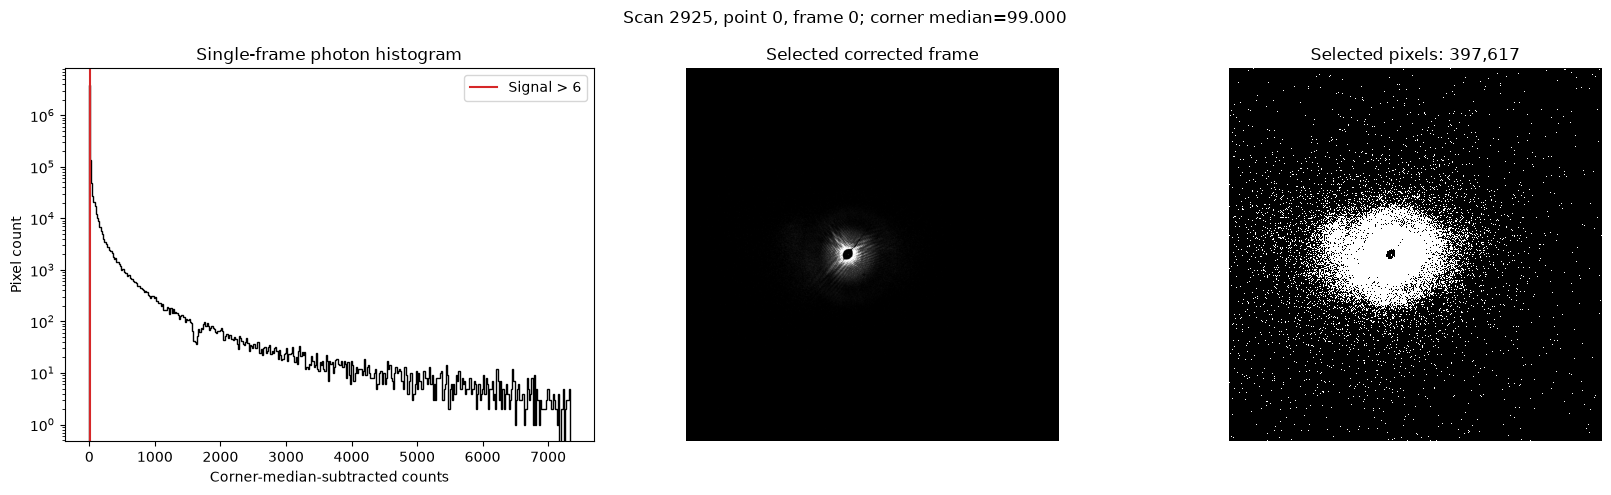

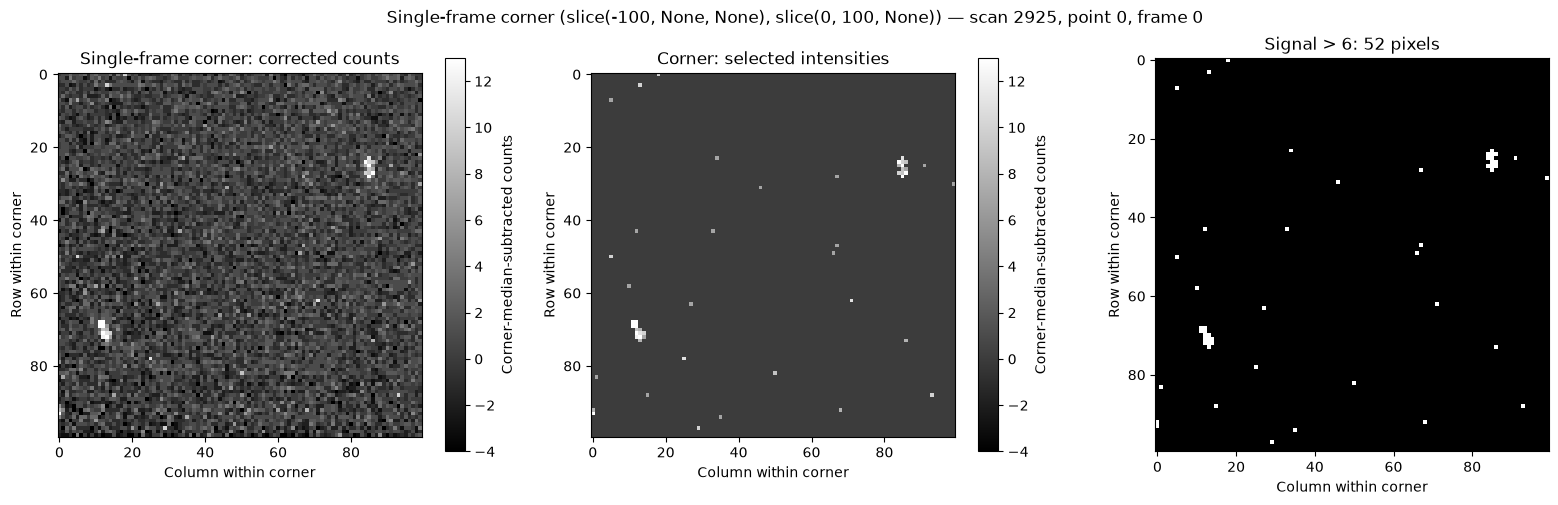

Loaded one diagnostic frame from: /media/riccardo/EXT_16TB1/DATA/P04/11022228/raw/2602_orbitronics_02925/marana/2602_orbitronics_02925_000000.nx
Threshold rule: signal > 6; all other pixels zero
Signal shown here = raw frame minus corner median (preview background estimate).
photon_only_frame contains 397617 nonzero pixels; every rejected pixel is zero.


In [6]:
if RUN_PHOTON_DIAGNOSTIC:
    _, diagnostic_files = scan_files(RAW_ROOT, PREFIX, PHOTON_DIAGNOSTIC_SCAN)
    diagnostic_point_numbers = detector_file_point_indices(diagnostic_files)
    diagnostic_matches = np.flatnonzero(
        diagnostic_point_numbers == PHOTON_DIAGNOSTIC_POINT
    )
    if len(diagnostic_matches) != 1:
        raise ValueError(
            f"Point {PHOTON_DIAGNOSTIC_POINT} is absent or duplicated in "
            f"scan {PHOTON_DIAGNOSTIC_SCAN}"
        )
    diagnostic_path = diagnostic_files[int(diagnostic_matches[0])]
    with h5py.File(diagnostic_path) as handle:
        detector_data = handle[DETECTOR_DATASET]
        if detector_data.ndim == 2:
            if PHOTON_DIAGNOSTIC_FRAME != 0:
                raise IndexError("A 2-D detector file only has frame 0")
            diagnostic_raw_frame = np.asarray(detector_data, dtype=np.float32)
        elif detector_data.ndim == 3:
            if not 0 <= PHOTON_DIAGNOSTIC_FRAME < detector_data.shape[0]:
                raise IndexError(
                    f"Frame {PHOTON_DIAGNOSTIC_FRAME} is outside "
                    f"0..{detector_data.shape[0] - 1}"
                )
            diagnostic_raw_frame = np.asarray(
                detector_data[PHOTON_DIAGNOSTIC_FRAME], dtype=np.float32
            )
        else:
            raise ValueError(
                f"Expected 2-D or 3-D detector data, got {detector_data.shape}"
            )

    diagnostic_corner_values = diagnostic_raw_frame[PHOTON_DIAGNOSTIC_CORNER]
    diagnostic_background = float(np.median(diagnostic_corner_values))
    diagnostic_corrected_frame = diagnostic_raw_frame - diagnostic_background
    photon_selection = (np.ones_like(diagnostic_corrected_frame, dtype=bool)
                        if PHOTON_LEVEL is None else diagnostic_corrected_frame > PHOTON_LEVEL)
    photon_only_frame = np.where(
        photon_selection, diagnostic_corrected_frame, 0
    ).astype(np.float32)

    finite_values = diagnostic_corrected_frame[np.isfinite(diagnostic_corrected_frame)]
    histogram_range = PHOTON_DIAGNOSTIC_HIST_RANGE
    if histogram_range is None:
        histogram_range = tuple(np.percentile(finite_values, [0.01, 99.99]))
    if histogram_range[0] >= histogram_range[1]:
        raise ValueError("PHOTON_DIAGNOSTIC_HIST_RANGE must have increasing bounds")

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    axes[0].hist(
        finite_values, bins=PHOTON_DIAGNOSTIC_HIST_BINS,
        range=histogram_range, histtype="step", color="black", log=True,
    )
    if PHOTON_LEVEL is not None:
        axes[0].axvline(PHOTON_LEVEL, color="tab:red", label=f"Signal > {PHOTON_LEVEL:g}")
    axes[0].set(
        xlabel="Corner-median-subtracted counts", ylabel="Pixel count",
        title="Single-frame photon histogram",
    )
    if PHOTON_LEVEL is not None:
        axes[0].legend()
    raw_low, raw_high = np.percentile(diagnostic_corrected_frame, [1, 99.9])
    axes[1].imshow(
        diagnostic_corrected_frame, cmap="gray", vmin=raw_low, vmax=raw_high
    )
    axes[1].set_title("Selected corrected frame")
    axes[2].imshow(photon_selection, cmap="gray", interpolation="nearest")
    axes[2].set_title(f"Selected pixels: {np.count_nonzero(photon_selection):,}")
    for axis in axes[1:]:
        axis.axis("off")
    fig.suptitle(
        f"Scan {PHOTON_DIAGNOSTIC_SCAN}, point {PHOTON_DIAGNOSTIC_POINT}, "
        f"frame {PHOTON_DIAGNOSTIC_FRAME}; corner median={diagnostic_background:.3f}"
    )
    fig.tight_layout()
    # Inspect individual pixels in the same corner of this single frame.
    corner_corrected = diagnostic_corrected_frame[PHOTON_DIAGNOSTIC_CORNER]
    corner_photon_only = photon_only_frame[PHOTON_DIAGNOSTIC_CORNER]
    corner_selected = photon_selection[PHOTON_DIAGNOSTIC_CORNER]
    corner_finite = corner_corrected[np.isfinite(corner_corrected)]
    corner_low, corner_high = np.percentile(corner_finite, [1, 99.9])
    corner_low = min(float(corner_low), 0.0)
    corner_high = max(float(corner_high), (PHOTON_LEVEL if PHOTON_LEVEL is not None else 0), corner_low + 1.0)
    corner_fig, corner_axes = plt.subplots(1, 3, figsize=(16, 5))
    for axis, values, title in zip(
        corner_axes[:2], (corner_corrected, corner_photon_only),
        ("Single-frame corner: corrected counts", "Corner: selected intensities"),
    ):
        artist = axis.imshow(
            values, cmap="gray", vmin=corner_low, vmax=corner_high,
            interpolation="nearest", origin="upper",
        )
        axis.set_title(title)
        corner_fig.colorbar(artist, ax=axis, label="Corner-median-subtracted counts")
    corner_axes[2].imshow(
        corner_selected, cmap="gray", vmin=0, vmax=1,
        interpolation="nearest", origin="upper",
    )
    corner_axes[2].set_title(
        (f"Signal > {PHOTON_LEVEL:g}: {np.count_nonzero(corner_selected):,} pixels"
         if PHOTON_LEVEL is not None else "Threshold disabled")
    )
    for axis in corner_axes:
        axis.set(xlabel="Column within corner", ylabel="Row within corner")
    corner_fig.suptitle(
        f"Single-frame corner {PHOTON_DIAGNOSTIC_CORNER} — "
        f"scan {PHOTON_DIAGNOSTIC_SCAN}, point {PHOTON_DIAGNOSTIC_POINT}, "
        f"frame {PHOTON_DIAGNOSTIC_FRAME}"
    )
    corner_fig.tight_layout()
    plt.show()
    print("Loaded one diagnostic frame from:", diagnostic_path)
    print("Threshold rule:", f"signal > {PHOTON_LEVEL:g}; all other pixels zero"
          if PHOTON_LEVEL is not None else "disabled")
    print("Signal shown here = raw frame minus corner median (preview background estimate).")
    print("photon_only_frame contains", np.count_nonzero(photon_only_frame),
          "nonzero pixels; every rejected pixel is zero.")
else:
    print("Single-frame photon diagnostic disabled.")


## Export the detector hologram for Paint
Run the next cell to save **`DETECTOR_MASK_PRE_PNG`**. It displays `log(1 + intensity)` in **viridis**, with optional subtraction of a Gaussian-smoothed log background to reveal faint features around bright scattering. This affects the template only, not the retrieval data.

Open the `_pre.png` in Paint, mark excluded pixels pure red `(255,0,0)`, then **Save As `DETECTOR_MASK_PNG`** (without `_pre`). Keep the dimensions unchanged. You can adjust the display settings and rerun this cell to regenerate the template; the final painted mask is never overwritten. Then continue to the mask-loading cell below.


Hologram template saved: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/mask_pixel_2923_pre.png
Paint pure-red exclusions, then Save As: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/mask_pixel_2923.png
Native pixel dimensions: (2048, 2048)


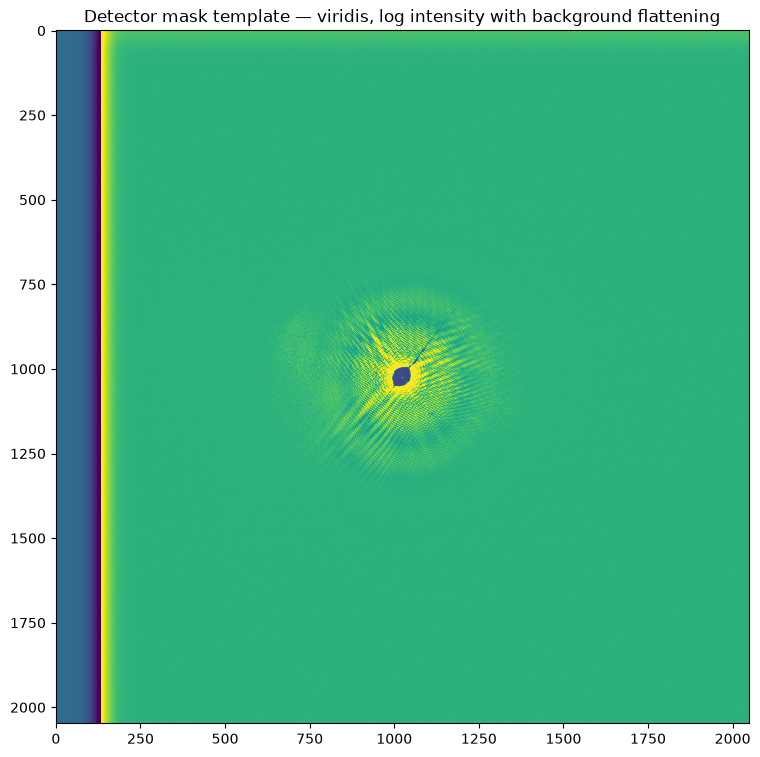

In [7]:
detector_template_hologram = centered(reference_raw, DETECTOR_CENTER)
save_detector_mask_template(
    detector_template_hologram, DETECTOR_MASK_PRE_PNG,
    flatten_sigma=DETECTOR_MASK_FLATTEN_SIGMA,
    flatten_strength=DETECTOR_MASK_FLATTEN_STRENGTH,
    percentiles=DETECTOR_MASK_DISPLAY_PERCENTILES)
print("Hologram template saved:", DETECTOR_MASK_PRE_PNG)
print("Paint pure-red exclusions, then Save As:", DETECTOR_MASK_PNG)
print("Native pixel dimensions:", detector_template_hologram.shape[::-1])
from PIL import Image
with Image.open(DETECTOR_MASK_PRE_PNG) as template_image:
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(np.asarray(template_image), interpolation="nearest")
    ax.set_title("Detector mask template — viridis, log intensity with background flattening")
    plt.show()
del detector_template_hologram


## Average the saturated reference and prepare masks

Set `PHOTON_LEVEL` in the first settings cell (currently 6) to apply `image[image <= PHOTON_LEVEL] = 0` after dark subtraction on each frame, before averaging. Surviving pixels retain their intensity. Each loop point is averaged separately. The saturated reference uses the same threshold. Dark frames and the raw average used for the corner fit are unthresholded.

Paint exclusions pure red in /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/mask_pixel_2923.png then rerun this cell
Dark corner: 44100 unmasked pixels, 44092 fit inliers
Image ≈ 0.72071 × dark + 27.942 counts (dark std 0.576 counts)
Dark variation is below 1 count in this corner; fitted scale may be unreliable.
Applied dark correction: 1 × dark + 0 counts (measured)
Thresholded 1/1 saturated files
Raw shape: (2048, 2048) prepared shape: (2048, 2048)


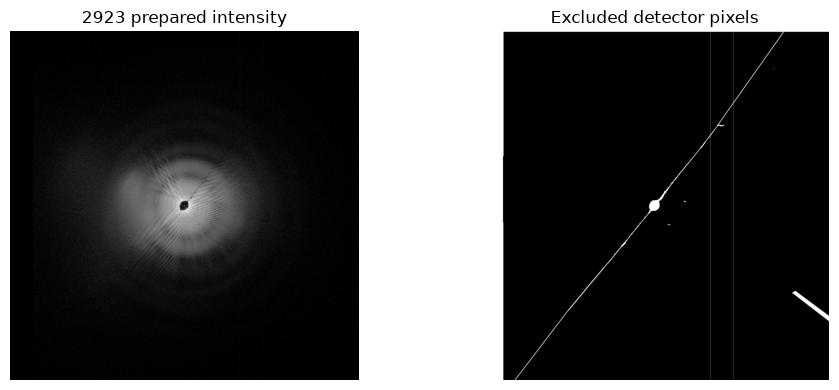

In [8]:
# Detector exclusions are on the centered detector grid. They are different
# from the object-space support above.
detector_mask_source = None
painted_detector_mask = prepare_painted_detector_mask(
    centered(reference_raw, DETECTOR_CENTER), DETECTOR_MASK_PNG,
    template_path=DETECTOR_MASK_PRE_PNG)
print("Paint exclusions pure red in", DETECTOR_MASK_PNG, "then rerun this cell")
# Fit image = scale * dark + offset on a quiet detector corner. The mask
# is prepared with the image so the same excluded pixels are omitted here.
zero_dark = np.zeros_like(dark)
raw_prepared, reference_mask, _, _ = prepare_point(
    reference_raw, zero_dark, DETECTOR_CENTER, None,
    CROP, BINNING, BEAMSTOP_RADIUS, SATURATION, detector_mask_source,
    centered_mask=painted_detector_mask,
)
dark_prepared, _, _, _ = prepare_point(
    dark, zero_dark, DETECTOR_CENTER, None,
    CROP, BINNING, BEAMSTOP_RADIUS, np.inf,
)
corner_rows, corner_cols = DARK_CORNER_ROI
if (corner_rows.stop > raw_prepared.shape[0]
        or corner_cols.stop > raw_prepared.shape[1]):
    raise ValueError("DARK_CORNER_ROI falls outside the prepared detector image")
corner_valid = ((reference_mask[DARK_CORNER_ROI] == 0)
                & np.isfinite(raw_prepared[DARK_CORNER_ROI])
                & np.isfinite(dark_prepared[DARK_CORNER_ROI]))
dark_corner = dark_prepared[DARK_CORNER_ROI][corner_valid].astype(float)
image_corner = raw_prepared[DARK_CORNER_ROI][corner_valid].astype(float)
if dark_corner.size < 50:
    raise ValueError("Fewer than 50 unmasked pixels remain in DARK_CORNER_ROI")
fit_scale = np.nan
fit_offset = np.nan
fit_inliers = np.ones(dark_corner.size, dtype=bool)
if DARK_SCAN is not None and np.std(dark_corner) > 1e-9:
    design = np.column_stack((dark_corner, np.ones_like(dark_corner)))
    for _ in range(4):
        fit_scale, fit_offset = np.linalg.lstsq(
            design[fit_inliers], image_corner[fit_inliers], rcond=None,
        )[0]
        residual = image_corner - (fit_scale * dark_corner + fit_offset)
        center = np.median(residual[fit_inliers])
        sigma = 1.4826 * np.median(np.abs(residual[fit_inliers] - center))
        if sigma < 1e-9:
            break
        revised = np.abs(residual - center) <= 4 * sigma
        if revised.sum() < 50:
            break
        fit_inliers = revised
print(f"Dark corner: {dark_corner.size} unmasked pixels, "
      f"{fit_inliers.sum()} fit inliers")
print(f"Image ≈ {fit_scale:.5g} × dark + {fit_offset:.5g} counts "
      f"(dark std {np.std(dark_corner):.4g} counts)")
if np.std(dark_corner) < 1:
    print("Dark variation is below 1 count in this corner; fitted scale may be unreliable.")
if DARK_CORRECTION_MODE == "measured":
    dark_scale, dark_offset = 1.0, 0.0
elif DARK_CORRECTION_MODE == "corner_fit":
    if not np.isfinite(fit_scale) or fit_scale <= 0:
        raise ValueError("Corner dark scale is not positive and finite; choose manual or measured")
    dark_scale, dark_offset = float(fit_scale), float(fit_offset)
elif DARK_CORRECTION_MODE == "manual":
    dark_scale, dark_offset = float(DARK_MANUAL_SCALE), float(DARK_MANUAL_OFFSET)
    if not np.isfinite(dark_scale) or dark_scale <= 0 or not np.isfinite(dark_offset):
        raise ValueError("Manual dark scale must be positive and scale/offset finite")
else:
    raise ValueError("DARK_CORRECTION_MODE must be measured, corner_fit, or manual")
dark_for_subtraction = dark_scale * dark + dark_offset
print(f"Applied dark correction: {dark_scale:.5g} × dark + "
      f"{dark_offset:.5g} counts ({DARK_CORRECTION_MODE})")
# Keep the raw average for the dark fit and saturation mask. Thresholding
# must happen on individual frames after the chosen dark correction is known.
reference_corrected = reference_raw - dark_for_subtraction
if PHOTON_LEVEL is not None:
    reference_sum = np.zeros_like(reference_raw, dtype=np.float64)
    reference_frame_count = 0
    for index, path in enumerate(sat_files):
        with h5py.File(path) as handle:
            data = handle[DETECTOR_DATASET]
            frame_count = (len(SATURATED_FRAME_INDICES) if SATURATED_FRAME_INDICES is not None
                           else (1 if data.ndim == 2 else data.shape[0]))
        reference_sum += frame_count * point_mean(
            path, frame_indices=SATURATED_FRAME_INDICES, dark=dark_for_subtraction, photon_level=PHOTON_LEVEL,
        )
        reference_frame_count += frame_count
        print(f"Thresholded {index + 1}/{len(sat_files)} saturated files", end="\r")
    print()
    reference_corrected = (reference_sum / reference_frame_count).astype(np.float32)
reference, _, _, geometry = prepare_point(
    reference_corrected, zero_dark, DETECTOR_CENTER, None,
    CROP, BINNING, BEAMSTOP_RADIUS, SATURATION, detector_mask_source,
    centered_mask=painted_detector_mask,
)
print("Raw shape:", reference_raw.shape, "prepared shape:", reference.shape)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(np.log1p(np.maximum(reference, 0)), cmap="gray")
axes[0].set_title(f"{SATURATED_SCAN} prepared intensity")
axes[1].imshow(reference_mask, cmap="gray")
axes[1].set_title("Excluded detector pixels")
for ax in axes: ax.axis("off")
plt.tight_layout()

# Inspect the painted support against the FTH image from this scan.
reference_for_fth = np.where(reference_mask, 0, reference)
fth_magnitude = np.abs(np.fft.ifftshift(
    np.fft.ifft2(np.fft.fftshift(reference_for_fth))
))

In [9]:
plt.close("all")
fit_scale, fit_offset

(np.float64(0.7207134559125461), np.float64(27.94187135473395))

Applied subtraction, unmasked corner: mean 0.14508549869060516 median 0.15000152587890625 std 0.46783995628356934


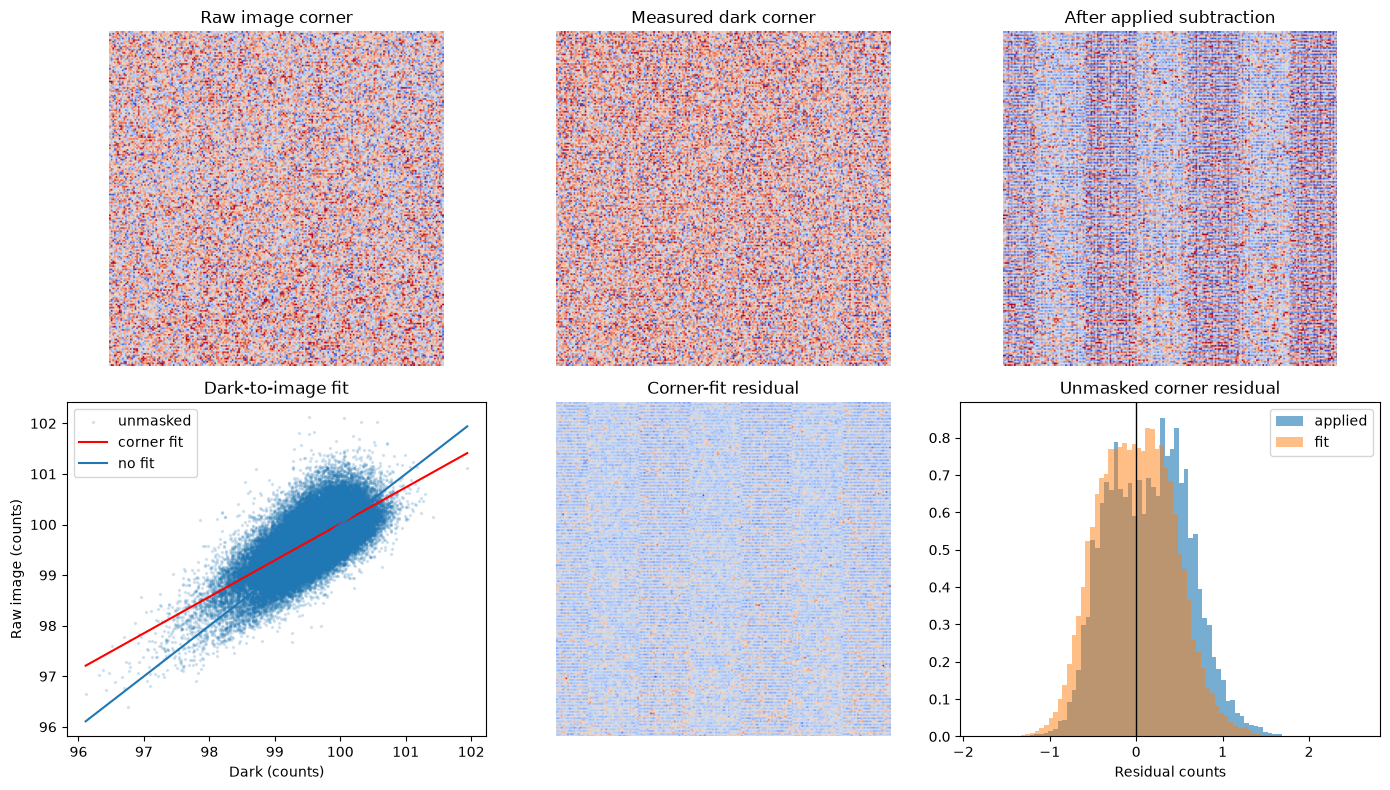

In [10]:
# Inspect the same unmasked detector corner before and after subtraction.
corner_raw = raw_prepared[DARK_CORNER_ROI]
corner_dark = dark_prepared[DARK_CORNER_ROI]
corner_corrected = corner_raw - (dark_scale * corner_dark + dark_offset)
corner_fit_residual = corner_raw - (fit_scale * corner_dark + fit_offset)
masked_view = lambda values: np.ma.array(values, mask=~corner_valid)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, values, title in zip(
    axes[0], (corner_raw, corner_dark, corner_corrected),
    ("Raw image corner", "Measured dark corner", "After applied subtraction"),
):
    view = masked_view(values)
    ax.imshow(view, cmap="coolwarm", vmin=np.percentile(view.compressed(), 2),
              vmax=np.percentile(view.compressed(), 98))
    ax.set_title(title)
    ax.axis("off")
axes[1, 0].scatter(dark_corner, image_corner, s=2, alpha=0.15, label="unmasked")
if np.isfinite(fit_scale):
    xline = np.linspace(dark_corner.min(), dark_corner.max(), 100)
    axes[1, 0].plot(xline, fit_scale * xline + fit_offset, "r", label="corner fit")
    
    axes[1, 0].plot(xline, xline, label="no fit")
    
axes[1, 0].set(xlabel="Dark (counts)", ylabel="Raw image (counts)",
               title="Dark-to-image fit")
axes[1, 0].legend()
axes[1, 1].imshow(masked_view(corner_fit_residual), cmap="coolwarm")
axes[1, 1].set_title("Corner-fit residual")
axes[1, 1].axis("off")
axes[1, 2].hist(corner_corrected[corner_valid], bins=80, alpha=0.6,
                label="applied", density=True)
if np.isfinite(fit_scale):
    axes[1, 2].hist(corner_fit_residual[corner_valid], bins=80, alpha=0.5,
                    label="fit", density=True)
axes[1, 2].axvline(0, color="black", linewidth=1)
axes[1, 2].set(xlabel="Residual counts", title="Unmasked corner residual")
axes[1, 2].legend()
plt.tight_layout()
print("Applied subtraction, unmasked corner: mean",
      float(np.mean(corner_corrected[corner_valid])), "median",
      float(np.median(corner_corrected[corner_valid])), "std",
      float(np.std(corner_corrected[corner_valid])))

In [11]:
plt.close("all")
%matplotlib qt
import scipy
fig,ax=plt.subplots()
ax.imshow(scipy.ndimage.gaussian_filter(dark, sigma=0), vmin=98, vmax=100)
fig,ax=plt.subplots()
ax.imshow(scipy.ndimage.gaussian_filter((reference_raw).astype(float), sigma=0), vmin=-1, vmax=200)

## Stream prepared loop points into a repository cache

In [12]:
CACHE.parent.mkdir(parents=True, exist_ok=True)
partial = CACHE.with_suffix(".partial.h5")
config = {
    "loop_point_numbers": loop_point_indices.tolist(),
    "loop_frame_indices": LOOP_FRAME_INDICES,
    "saturated_frame_indices": SATURATED_FRAME_INDICES,
    "dark_frame_indices": DARK_FRAME_INDICES,
    "raw_root": str(RAW_ROOT), "prefix": PREFIX,
    "saturated_scan": SATURATED_SCAN, "loop_scan": LOOP_SCAN,
    "dark_scan": DARK_SCAN, "detector_center": DETECTOR_CENTER,
    "dark_correction_mode": DARK_CORRECTION_MODE,
    "dark_scale_applied": dark_scale, "dark_offset_applied": dark_offset,
    "dark_corner_fit_scale": float(fit_scale),
    "dark_corner_fit_offset": float(fit_offset),
    "dark_corner_roi": [corner_rows.start, corner_rows.stop,
                        corner_cols.start, corner_cols.stop],
    "loop_point_step": LOOP_POINT_STEP,
    "support_png": str(SUPPORT_PNG), "detector_mask_png": (
        None if DETECTOR_MASK_PNG is None else str(DETECTOR_MASK_PNG)),
    "crop_raw_pixels": CROP, "binning": BINNING,
    "retrieval_crop": RETRIEVAL_CROP,
    "retrieval_binning": RETRIEVAL_BINNING,
    "retrieval_modes": RETRIEVAL_MODES,
    "beamstop_radius_raw_pixels": BEAMSTOP_RADIUS,
    "detector_mask_source": "painted_png",
    "detector_mask_coordinates": "centered_detector",
    "support_loading": "painted_png_in_01",
    "saturation": SATURATION, "photon_level": PHOTON_LEVEL,
    "single_photon_counting": PHOTON_LEVEL is not None,
    "photon_threshold_rule": "dark-correct each frame; zero values <= threshold; average",
}
with h5py.File(partial, "w") as h:
    h.attrs["workflow"] = "aperiodic_preprocessed"
    h.attrs["config_json"] = json.dumps(config)
    h.attrs["photon_energy_eV"] = ENERGY_EV
    h.create_dataset("saturated_hologram", data=reference, compression="lzf")
    h.create_dataset("saturated_mask", data=reference_mask, compression="gzip")
    _, automatic_mask, _, _ = prepare_point(
        reference_raw, zero_dark, DETECTOR_CENTER, None,
        CROP, BINNING, BEAMSTOP_RADIUS, SATURATION)
    h.create_dataset("saturated_automatic_mask", data=automatic_mask, compression="gzip")
    h.create_dataset("saturated_current_A", data=sat_current)
    h.create_dataset("saturated_point_numbers", data=sat_point_indices)
    h.create_dataset("saturated_file_names", data=np.asarray(
        [str(path) for path in sat_files], dtype=h5py.string_dtype()))
    h.create_dataset("loop_current_A", data=loop_current)
    h.create_dataset("loop_indices", data=loop_point_indices)
    h.create_dataset("loop_file_names", data=np.asarray(
        [str(path) for path in loop_files], dtype=h5py.string_dtype()))
    stack = h.create_dataset(
        "loop_holograms", (len(loop_files), *reference.shape),
        dtype="float32", chunks=(1, *reference.shape), compression="lzf",
    )
    masks = h.create_dataset(
        "loop_masks", (len(loop_files), *reference.shape),
        dtype="uint8", chunks=(1, *reference.shape), compression="gzip",
    )
    automatic_masks = h.create_dataset(
        "loop_automatic_masks", (len(loop_files), *reference.shape),
        dtype="uint8", chunks=(1, *reference.shape), compression="gzip")
    for index, path in enumerate(loop_files):
        raw_minus_dark = point_mean(path, frame_indices=LOOP_FRAME_INDICES, dark=dark_for_subtraction, photon_level=PHOTON_LEVEL)
        image, mask, this_support, _ = prepare_point(
            raw_minus_dark, np.zeros_like(dark_for_subtraction), DETECTOR_CENTER, None,
            CROP, BINNING, BEAMSTOP_RADIUS, SATURATION, detector_mask_source,
            centered_mask=painted_detector_mask,
        )
        _, automatic_mask, _, _ = prepare_point(
            raw_minus_dark, np.zeros_like(dark_for_subtraction), DETECTOR_CENTER, None,
            CROP, BINNING, BEAMSTOP_RADIUS, SATURATION)
        automatic_masks[index] = automatic_mask
        stack[index] = image
        masks[index] = mask
        print(f"Prepared {index+1}/{len(loop_files)} loop points", end="\r")
    print()
os.replace(partial, CACHE)
print("Saved repository cache:", CACHE, "size:", round(CACHE.stat().st_size/2**20, 1), "MiB")

Prepared 101/101 loop points
Saved repository cache: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/processed/preprocessed_2925_2923.h5 size: 1141.0 MiB


## Check cached content

In [13]:
with h5py.File(CACHE) as h:
    print("Saturated:", h["saturated_hologram"].shape,
          "loop:", h["loop_holograms"].shape,
          "support: loaded from PNG in 01")
    first = h["loop_holograms"][0]
    last = h["loop_holograms"][-1]
    first_mask = h["loop_masks"][0]
    last_mask = h["loop_masks"][-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, im, title in zip(axes, [first-reference, last-reference],
                         ["First state minus saturation", "Last state minus saturation"]):
    ax.imshow(np.sign(im)*np.log1p(np.abs(im)), cmap="coolwarm")
    ax.set_title(title); ax.axis("off")
plt.tight_layout()
# The corner should remain near its expected background level across states.
# These are saved, dark-corrected images; no raw files are reread here.
fig, ax = plt.subplots(figsize=(7, 4))
for name, image, mask in (
    ("saturated", reference, reference_mask),
    ("first loop", first, first_mask),
    ("last loop", last, last_mask),
):
    values = image[DARK_CORNER_ROI][mask[DARK_CORNER_ROI] == 0]
    print(f"{name} corrected corner: median={np.median(values):.3f}, "
          f"mean={np.mean(values):.3f}, std={np.std(values):.3f} counts")
    ax.hist(values, bins=80, histtype="step", density=True, label=name)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Dark-corrected corner (counts)", ylabel="Density",
       title="Corner background across field states")
ax.legend()
plt.tight_layout()


Saturated: (2048, 2048) loop: (101, 2048, 2048) support: loaded from PNG in 01
saturated corrected corner: median=0.064, mean=0.142, std=0.213 counts
first loop corrected corner: median=0.067, mean=0.151, std=0.226 counts
last loop corrected corner: median=0.065, mean=0.148, std=0.224 counts


In [14]:
plt.close("all")